In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Enable inline plotting for Jupyter Notebook
%matplotlib inline


In [2]:
# Load or create a sample dataset
# For demonstration, we create a random sample dataset with features typically found in customer datasets
np.random.seed(42)
data = pd.DataFrame({
    'customer_id': np.arange(1, 101),
    'age': np.random.randint(18, 70, size=100),
    'tenure': np.random.randint(1, 15, size=100),
    'monthly_spending': np.random.uniform(50, 500, size=100),
    'num_products': np.random.randint(1, 5, size=100)
})

# Display the first few rows of the dataset
data.head()


,customer_id,age,tenure,monthly_spending,num_products
0,1,56,13,172.459512,2
1,2,69,1,341.460554,3
2,3,46,9,50.234170,2
3,4,32,7,208.655985,2
4,5,60,9,187.151566,2


In [3]:
# Preprocess the data - Handle missing values
# Check for missing values and handle them if present (e.g., fill or drop)
data.isnull().sum()
# Assuming no missing values here, but you can handle as needed


customer_id         0
age                 0
tenure              0
monthly_spending    0
num_products        0
dtype: int64

In [4]:
# Normalize numerical columns
# Select the features we will use for clustering
features = ['age', 'tenure', 'monthly_spending', 'num_products']
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data[features])

# Convert back to DataFrame for easier viewing
data_scaled = pd.DataFrame(data_scaled, columns=features)
data_scaled.head()


,age,tenure,monthly_spending,num_products
0,0.853003,1.253034,-0.876750,-0.388493
1,1.729608,-1.730380,0.475724,0.514978
2,0.178692,0.258563,-1.854889,-0.388493
3,-0.765343,-0.238673,-0.587079,-0.388493
4,1.122728,0.258563,-0.759173,-0.388493


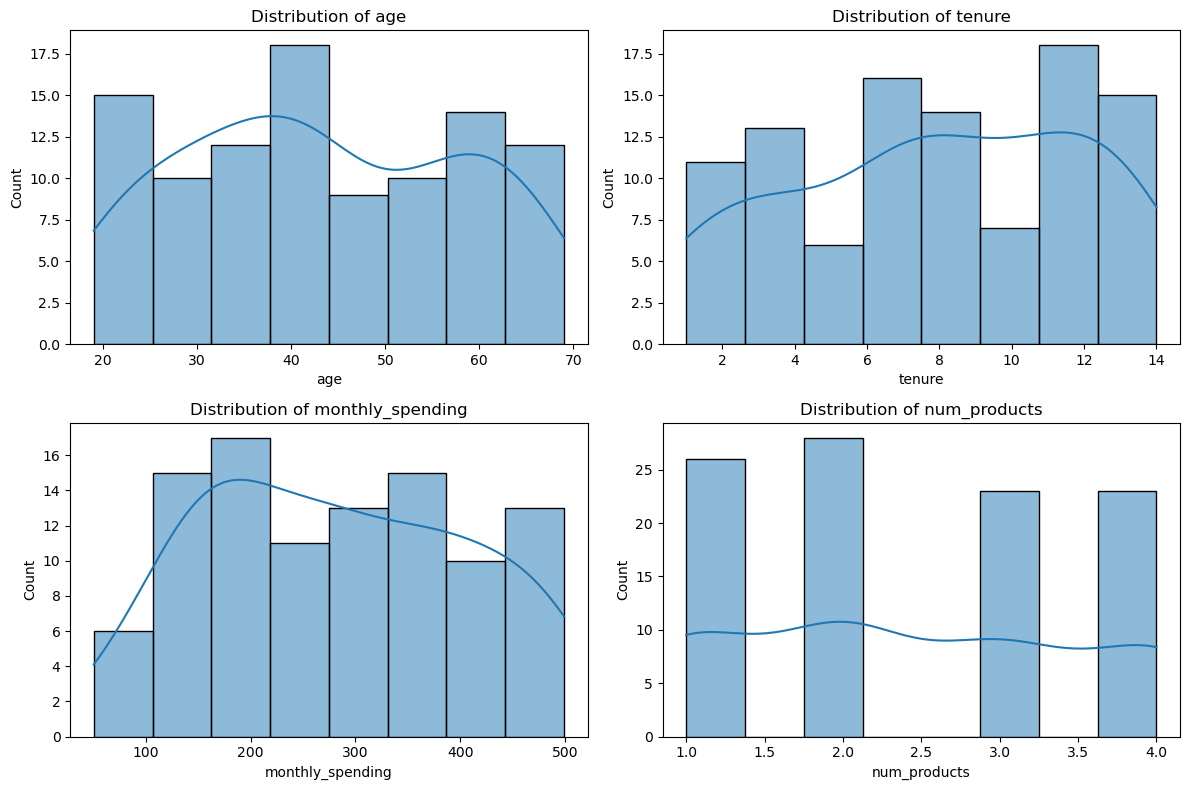

In [5]:
# Visualize the distribution of features
# Histograms to check feature distribution
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, feature in enumerate(features):
    sns.histplot(data[feature], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {feature}')
plt.tight_layout()
plt.show()


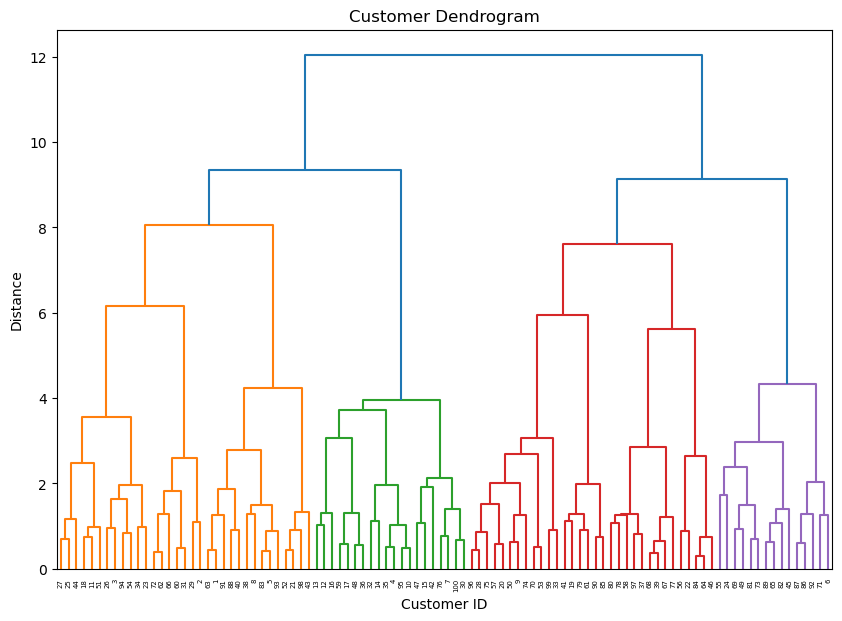

In [6]:
# Plot Dendrogram to visualize the clustering process
# Using linkage for dendrogram visualization
linked = linkage(data_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(linked, orientation='top', labels=data['customer_id'].values, distance_sort='descending', show_leaf_counts=False)
plt.title('Customer Dendrogram')
plt.xlabel('Customer ID')
plt.ylabel('Distance')
plt.show()


In [7]:
# Perform Hierarchical Clustering
# Assuming we choose 3 clusters based on dendrogram observation
cluster_model = AgglomerativeClustering(n_clusters=3, affinity='euclidean', linkage='ward')
data['cluster'] = cluster_model.fit_predict(data_scaled)

# Display the first few rows with cluster labels
data[['customer_id', 'cluster'] + features].head()


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_agglomerative.py:1005: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


,customer_id,cluster,age,tenure,monthly_spending,num_products
0,1,1,56,13,172.459512,2
1,2,1,69,1,341.460554,3
2,3,1,46,9,50.234170,2
3,4,2,32,7,208.655985,2
4,5,1,60,9,187.151566,2


In [8]:
# Analyze each cluster's characteristics
# Calculate summary statistics for each cluster
cluster_summary = data.groupby('cluster')[features].agg(['mean', 'median', 'std'])
cluster_summary


age                      tenure                   \
              mean median        std      mean median       std   
cluster                                                           
0        37.914894   36.0  14.332738  9.531915   10.0  3.694008   
1        53.484848   57.0  13.038695  8.363636    9.0  3.361716   
2        39.400000   40.5  10.292562  3.600000    3.0  2.583347   

        monthly_spending                         num_products                   
                    mean      median         std         mean median       std  
cluster                                                                         
0             372.870776  380.847254  106.550454     2.468085    2.0  1.080480  
1             192.964084  187.151566   75.969550     2.848485    3.0  1.148945  
2             215.440733  211.783469   78.201603     1.650000    2.0  0.670820

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


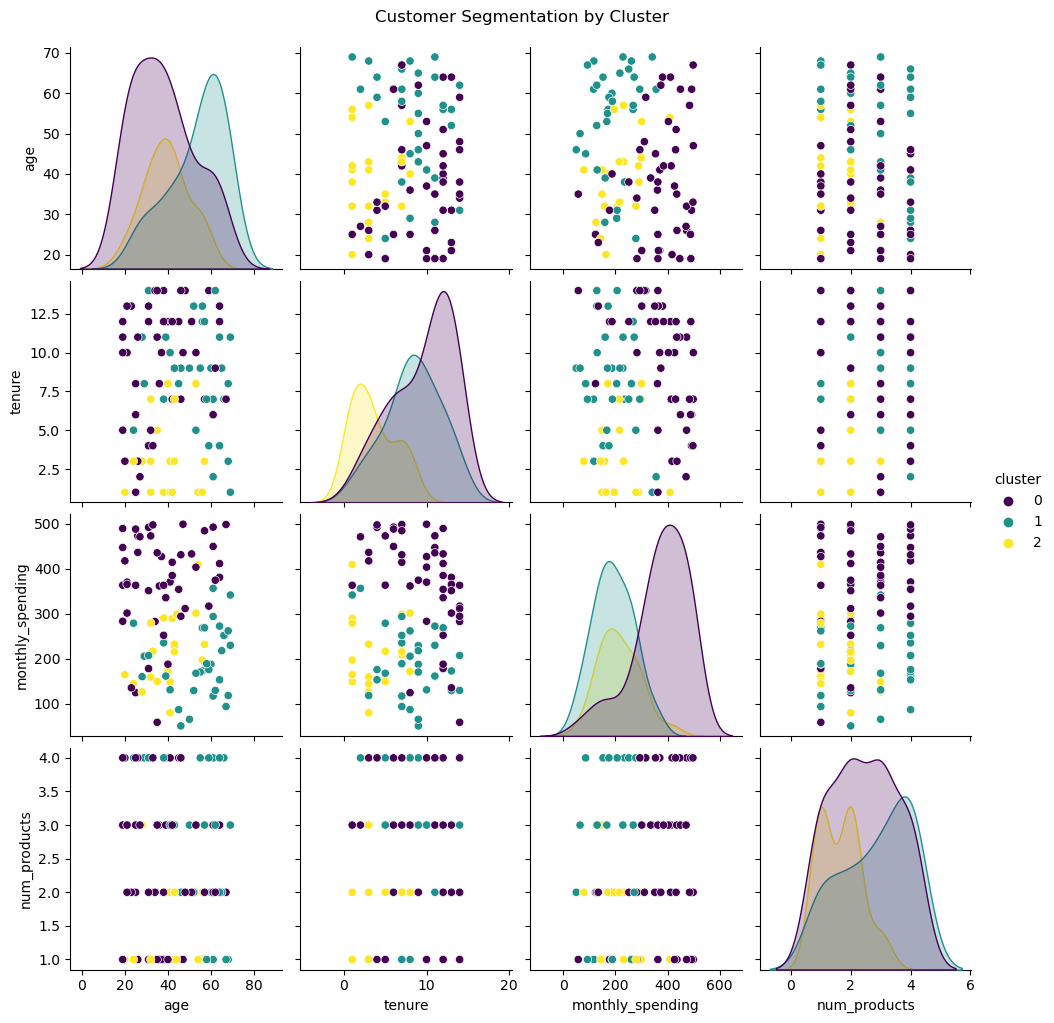

In [9]:
# Visualize clusters with scatter plots
# Pair plot with clusters colored differently
sns.pairplot(data, vars=features, hue='cluster', palette='viridis')
plt.suptitle("Customer Segmentation by Cluster", y=1.02)
plt.show()


In [10]:
# (Optional) Save your results to a file
# Saving the final dataset with cluster labels as a CSV
data.to_csv("customer_segments.csv", index=False)
